<a href="https://colab.research.google.com/github/nr868848-stack/employee_attrition_prediction/blob/main/Employee_Attrition_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# PROJECT: EMPLOYEE ATTRITION PREDICTION
# OBJECTIVE: Analyze employee turnover using Machine Learning
# ============================================================
4
# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

pd.set_option("display.max_columns", None)
np.random.seed(42)

print("Libraries imported successfully!")
print("Employee Attrition Prediction Project Started!")

Libraries imported successfully!
Employee Attrition Prediction Project Started!


In [ ]:
# ============================================================
# STEP 2: CREATE SIMULATED EMPLOYEE DATASET
# ============================================================

n = 2500

age = np.random.randint(21, 61, n)

monthly_income = np.random.randint(15000, 150001, n)

years_at_company = np.array([
    np.random.randint(0, min(41, a - 17))
    for a in age
])

years_experience = np.array([
    np.random.randint(y, max(y + 1, a - 17))
    for y, a in zip(years_at_company, age)
])

job_satisfaction = np.random.randint(1, 6, n)

work_life_balance = np.random.randint(1, 5, n)

years_since_promotion = np.array([
    np.random.randint(0, min(16, y + 1))
    for y in years_at_company
])

distance_from_home = np.random.randint(1, 51, n)

training_hours = np.random.randint(0, 81, n)

projects_completed = np.random.randint(1, 16, n)

overtime = np.random.choice(
    ["Yes", "No"],
    n,
    p=[0.35, 0.65]
)

department = np.random.choice(
    ["Sales", "Research", "IT", "HR", "Finance"],
    n
)

job_role = np.random.choice(
    ["Executive", "Analyst", "Manager", "Developer", "Specialist"],
    n
)

# Simulated probability of attrition
# This formula is created only for demonstration.

risk_score = (
    -2.0
    + 0.65 * (overtime == "Yes")
    + 0.45 * (job_satisfaction <= 2)
    + 0.35 * (work_life_balance <= 2)
    + 0.30 * (years_since_promotion >= 5)
    + 0.025 * distance_from_home
    - 0.015 * (monthly_income / 1000)
)

attrition_probability = 1 / (1 + np.exp(-risk_score))

attrition = np.random.binomial(
    1,
    attrition_probability
)

df = pd.DataFrame({
    "Age": age,
    "Monthly_Income": monthly_income,
    "Years_At_Company": years_at_company,
    "Years_Experience": years_experience,
    "Job_Satisfaction": job_satisfaction,
    "Work_Life_Balance": work_life_balance,
    "Years_Since_Promotion": years_since_promotion,
    "Distance_From_Home": distance_from_home,
    "Training_Hours": training_hours,
    "Projects_Completed": projects_completed,
    "Overtime": overtime,
    "Department": department,
    "Job_Role": job_role,
    "Attrition": attrition
})

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))

Dataset created successfully!
Dataset shape: (2500, 14)


,Age,Monthly_Income,Years_At_Company,Years_Experience,Job_Satisfaction,Work_Life_Balance,Years_Since_Promotion,Distance_From_Home,Training_Hours,Projects_Completed,Overtime,Department,Job_Role,Attrition
0,43,47235,11,25,1,3,6,35,22,4,No,HR,Executive,0
1,45,96395,6,10,5,4,5,37,27,10,Yes,Sales,Executive,1
2,57,25428,34,35,3,1,15,12,31,8,Yes,Finance,Analyst,1
3,24,100171,6,6,3,4,0,40,21,14,No,HR,Specialist,0
4,33,92660,14,15,3,1,12,8,61,4,Yes,Finance,Manager,0
5,38,128020,6,20,2,2,3,25,66,13,No,IT,Manager,0
6,49,54633,7,15,2,2,3,7,72,4,No,Sales,Specialist,0
7,50,137104,2,31,3,3,1,2,5,10,No,Sales,Analyst,0
8,58,29407,18,40,3,3,5,33,64,3,No,IT,Developer,0
9,48,88860,22,27,1,3,5,33,21,12,Yes,Research,Developer,0


In [ ]:
# ============================================================
# STEP 3: DATA EXPLORATION
# ============================================================

print("First 10 Records:")
display(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nAttrition Distribution:")
print(df["Attrition"].value_counts())

First 10 Records:


,Age,Monthly_Income,Years_At_Company,Years_Experience,Job_Satisfaction,Work_Life_Balance,Years_Since_Promotion,Distance_From_Home,Training_Hours,Projects_Completed,Overtime,Department,Job_Role,Attrition
0,43,47235,11,25,1,3,6,35,22,4,No,HR,Executive,0
1,45,96395,6,10,5,4,5,37,27,10,Yes,Sales,Executive,1
2,57,25428,34,35,3,1,15,12,31,8,Yes,Finance,Analyst,1
3,24,100171,6,6,3,4,0,40,21,14,No,HR,Specialist,0
4,33,92660,14,15,3,1,12,8,61,4,Yes,Finance,Manager,0
5,38,128020,6,20,2,2,3,25,66,13,No,IT,Manager,0
6,49,54633,7,15,2,2,3,7,72,4,No,Sales,Specialist,0
7,50,137104,2,31,3,3,1,2,5,10,No,Sales,Analyst,0
8,58,29407,18,40,3,3,5,33,64,3,No,IT,Developer,0
9,48,88860,22,27,1,3,5,33,21,12,Yes,Research,Developer,0



Dataset Shape:
(2500, 14)

Column Names:
['Age', 'Monthly_Income', 'Years_At_Company', 'Years_Experience', 'Job_Satisfaction', 'Work_Life_Balance', 'Years_Since_Promotion', 'Distance_From_Home', 'Training_Hours', 'Projects_Completed', 'Overtime', 'Department', 'Job_Role', 'Attrition']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Age                    2500 non-null   int64 
 1   Monthly_Income         2500 non-null   int64 
 2   Years_At_Company       2500 non-null   int64 
 3   Years_Experience       2500 non-null   int64 
 4   Job_Satisfaction       2500 non-null   int64 
 5   Work_Life_Balance      2500 non-null   int64 
 6   Years_Since_Promotion  2500 non-null   int64 
 7   Distance_From_Home     2500 non-null   int64 
 8   Training_Hours         2500 non-null   int64 
 9   Projects_Completed

,Age,Monthly_Income,Years_At_Company,Years_Experience,Job_Satisfaction,Work_Life_Balance,Years_Since_Promotion,Distance_From_Home,Training_Hours,Projects_Completed,Overtime,Department,Job_Role,Attrition
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500,2500,2500,2500.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,5,5,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,IT,Analyst,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1643,523,514,NaN
mean,40.478400,82978.094800,11.155200,16.718000,2.975600,2.522000,4.230000,25.243600,39.742000,7.936400,NaN,NaN,NaN,0.164800
std,11.571235,38669.718559,9.395277,10.417614,1.395343,1.125888,4.118335,14.279167,23.388558,4.324978,NaN,NaN,NaN,0.371074
min,21.000000,15181.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,NaN,NaN,NaN,0.000000
25%,30.000000,50999.500000,3.000000,8.000000,2.000000,2.000000,1.000000,13.000000,19.000000,4.000000,NaN,NaN,NaN,0.000000
50%,41.000000,82890.000000,9.000000,15.000000,3.000000,3.000000,3.000000,25.000000,40.000000,8.000000,NaN,NaN,NaN,0.000000
75%,50.000000,116294.250000,17.000000,25.000000,4.000000,4.000000,7.000000,38.000000,60.000000,12.000000,NaN,NaN,NaN,0.000000



Data Types:
Age                       int64
Monthly_Income            int64
Years_At_Company          int64
Years_Experience          int64
Job_Satisfaction          int64
Work_Life_Balance         int64
Years_Since_Promotion     int64
Distance_From_Home        int64
Training_Hours            int64
Projects_Completed        int64
Overtime                 object
Department               object
Job_Role                 object
Attrition                 int64
dtype: object

Missing Values:
Age                      0
Monthly_Income           0
Years_At_Company         0
Years_Experience         0
Job_Satisfaction         0
Work_Life_Balance        0
Years_Since_Promotion    0
Distance_From_Home       0
Training_Hours           0
Projects_Completed       0
Overtime                 0
Department               0
Job_Role                 0
Attrition                0
dtype: int64

Duplicate Records:
0

Attrition Distribution:
Attrition
0    2088
1     412
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 4: DATA CLEANING
# ============================================================

df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Handle missing numerical values
numeric_columns = df_clean.select_dtypes(
    include=["number"]
).columns

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].median()
    )

# Handle missing categorical values
categorical_columns = df_clean.select_dtypes(
    include=["object"]
).columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].fillna(
        df_clean[column].mode()[0]
    )

# Validate target values
df_clean = df_clean[
    df_clean["Attrition"].isin([0, 1])
].copy()

print("Data cleaning completed!")

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())

print("\nCleaned dataset shape:")
print(df_clean.shape)

Data cleaning completed!

Missing values after cleaning:
Age                      0
Monthly_Income           0
Years_At_Company         0
Years_Experience         0
Job_Satisfaction         0
Work_Life_Balance        0
Years_Since_Promotion    0
Distance_From_Home       0
Training_Hours           0
Projects_Completed       0
Overtime                 0
Department               0
Job_Role                 0
Attrition                0
dtype: int64

Duplicate rows after cleaning:
0

Cleaned dataset shape:
(2500, 14)


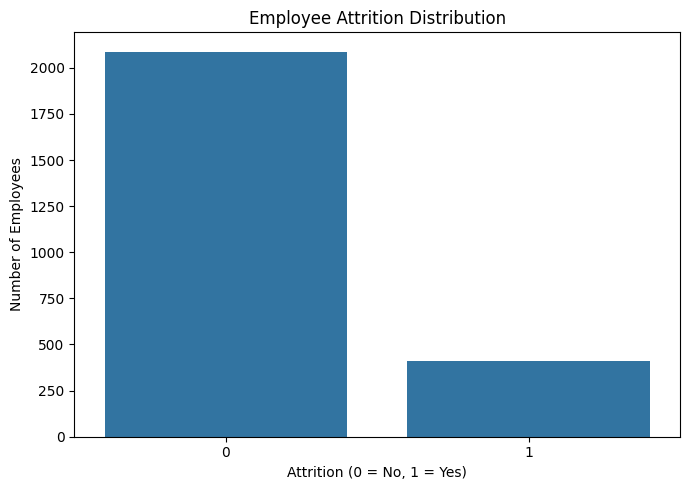

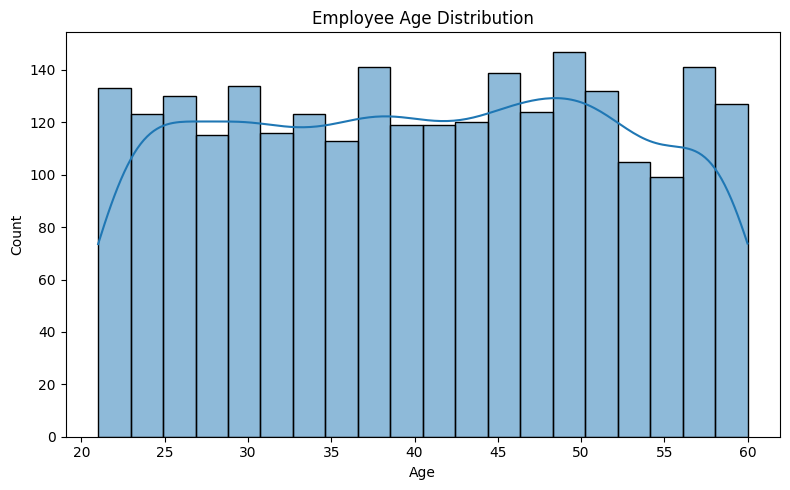

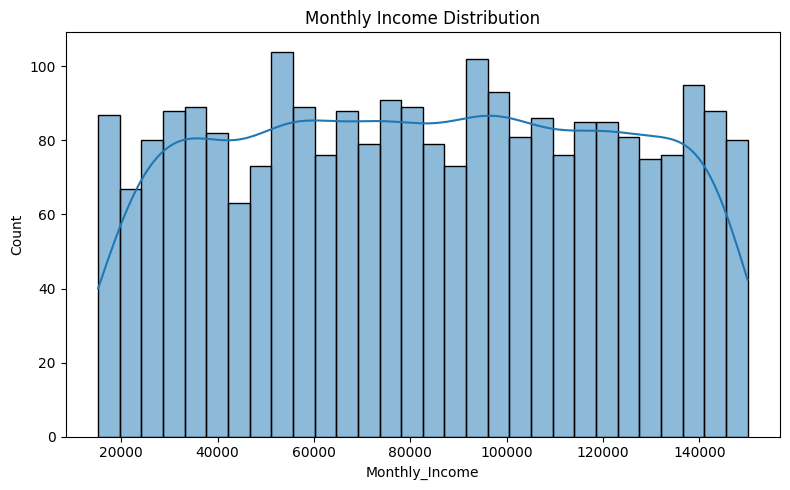

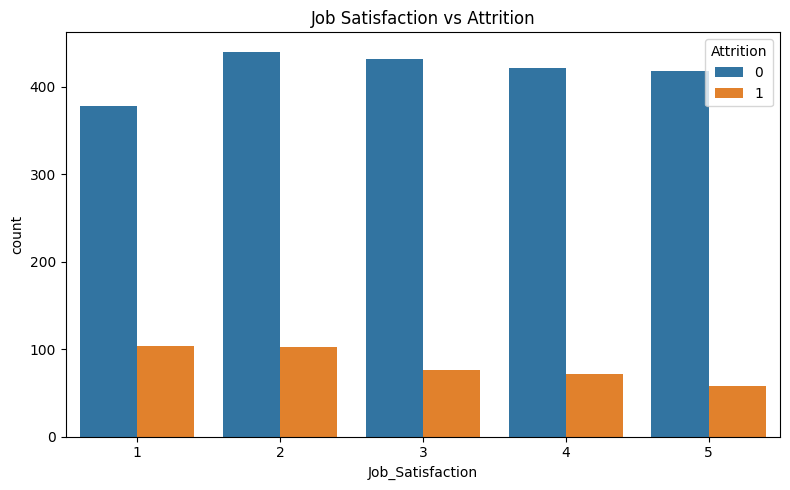

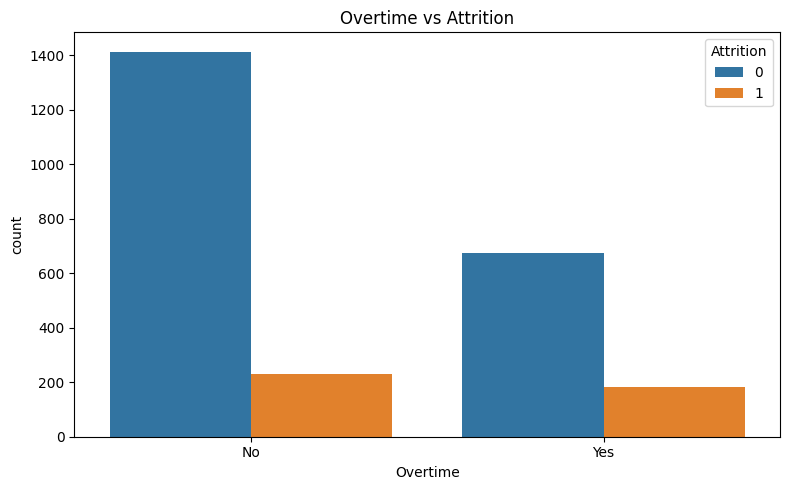

Simulated Attrition Rate by Department:


,Attrition
Department,
IT,0.177820
Finance,0.176349
Research,0.176230
HR,0.153693
Sales,0.140316


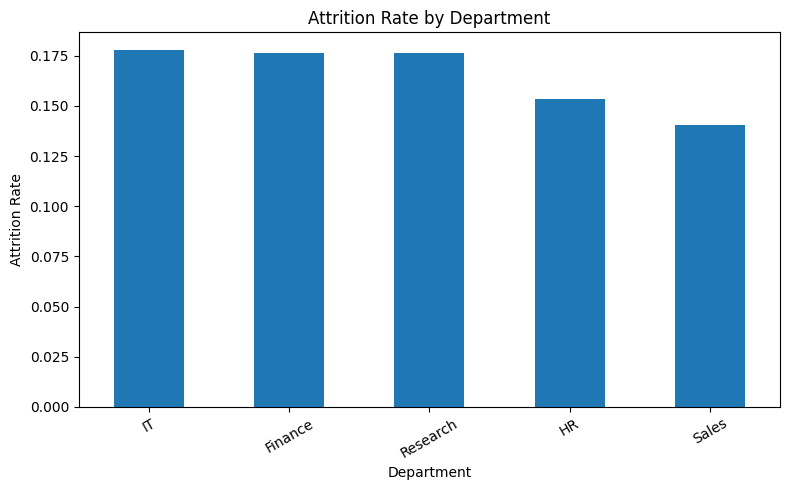

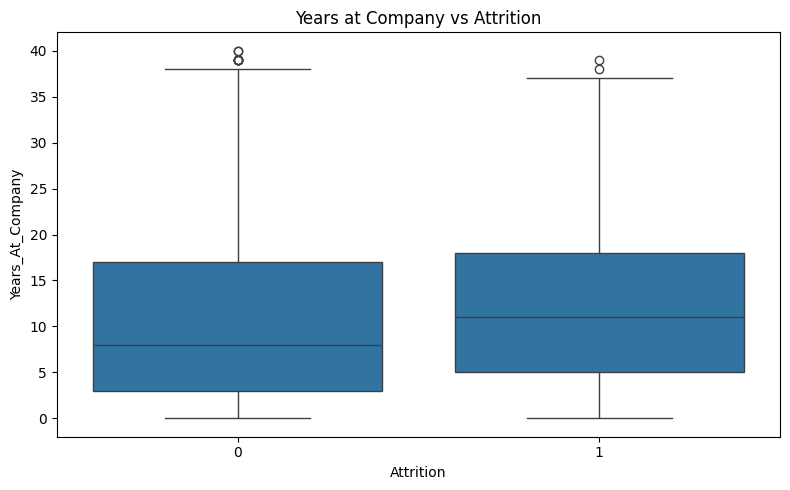

In [ ]:
# ============================================================
# STEP 5: EXPLORATORY DATA ANALYSIS
# ============================================================

# 1. Attrition distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition (0 = No, 1 = Yes)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()


# 2. Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Employee Age Distribution")
plt.tight_layout()
plt.show()


# 3. Monthly income distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="Monthly_Income",
    bins=30,
    kde=True
)

plt.title("Monthly Income Distribution")
plt.tight_layout()
plt.show()


# 4. Job satisfaction vs attrition

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Job_Satisfaction",
    hue="Attrition"
)

plt.title("Job Satisfaction vs Attrition")
plt.tight_layout()
plt.show()


# 5. Overtime vs attrition

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Overtime",
    hue="Attrition"
)

plt.title("Overtime vs Attrition")
plt.tight_layout()
plt.show()


# 6. Department-wise attrition rate

department_attrition = (
    df_clean.groupby("Department")["Attrition"]
    .mean()
    .sort_values(ascending=False)
)

print("Simulated Attrition Rate by Department:")
display(department_attrition)

department_attrition.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Attrition Rate by Department")
plt.ylabel("Attrition Rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 7. Years at company vs attrition

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Attrition",
    y="Years_At_Company"
)

plt.title("Years at Company vs Attrition")
plt.tight_layout()
plt.show()

Correlation Matrix:


,Age,Monthly_Income,Years_At_Company,Years_Experience,Job_Satisfaction,Work_Life_Balance,Years_Since_Promotion,Distance_From_Home,Training_Hours,Projects_Completed,Attrition
Age,1.00,-0.01,0.60,0.82,-0.01,-0.01,0.35,0.00,-0.05,0.01,-0.00
Monthly_Income,-0.01,1.00,-0.02,-0.01,0.02,-0.01,-0.01,-0.01,-0.01,0.00,-0.21
Years_At_Company,0.60,-0.02,1.00,0.79,-0.00,-0.00,0.57,0.00,-0.06,-0.02,0.06
Years_Experience,0.82,-0.01,0.79,1.00,0.00,0.00,0.45,-0.00,-0.06,0.00,0.02
Job_Satisfaction,-0.01,0.02,-0.00,0.00,1.00,0.03,0.03,0.00,0.01,-0.01,-0.09
Work_Life_Balance,-0.01,-0.01,-0.00,0.00,0.03,1.00,-0.02,0.00,0.02,0.01,-0.06
Years_Since_Promotion,0.35,-0.01,0.57,0.45,0.03,-0.02,1.00,-0.02,-0.02,-0.01,0.06
Distance_From_Home,0.00,-0.01,0.00,-0.00,0.00,0.00,-0.02,1.00,-0.01,-0.01,0.13
Training_Hours,-0.05,-0.01,-0.06,-0.06,0.01,0.02,-0.02,-0.01,1.00,-0.03,0.01
Projects_Completed,0.01,0.00,-0.02,0.00,-0.01,0.01,-0.01,-0.01,-0.03,1.00,-0.00


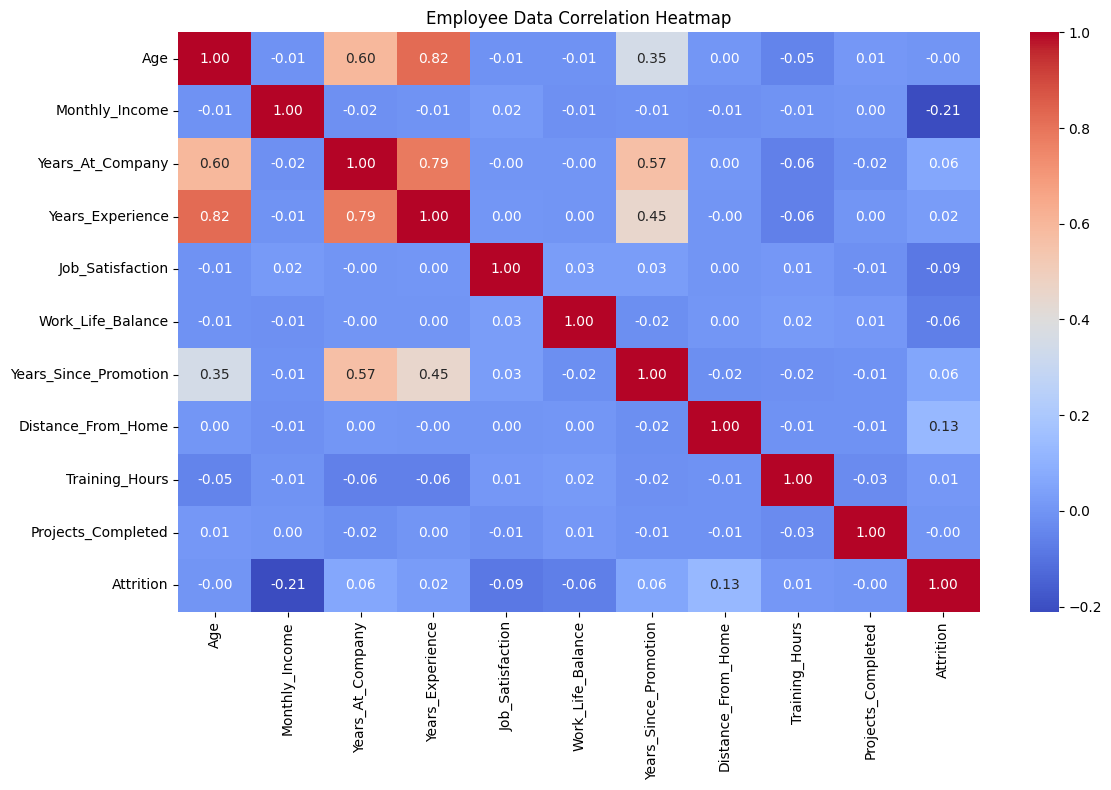


Correlation with Attrition:


,Attrition
Distance_From_Home,0.127604
Years_At_Company,0.060495
Years_Since_Promotion,0.055575
Years_Experience,0.022999
Training_Hours,0.007806
Age,-0.000662
Projects_Completed,-0.001695
Work_Life_Balance,-0.064234
Job_Satisfaction,-0.086518
Monthly_Income,-0.210316


In [ ]:
# ============================================================
# STEP 6: CORRELATION ANALYSIS
# ============================================================

numeric_df = df_clean.select_dtypes(
    include=["number"]
)

correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Employee Data Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nCorrelation with Attrition:")
display(
    correlation_matrix["Attrition"]
    .drop("Attrition")
    .sort_values(ascending=False)
)

In [ ]:
# ============================================================
# STEP 7: FEATURE ENGINEERING
# ============================================================

model_df = df_clean.copy()

# Create a new feature
model_df["Income_Per_Experience_Year"] = (
    model_df["Monthly_Income"] /
    (model_df["Years_Experience"] + 1)
)

# Separate features and target
X = model_df.drop(columns=["Attrition"])

y = model_df["Attrition"]

# Convert categorical columns into numeric columns
X = pd.get_dummies(
    X,
    columns=["Overtime", "Department", "Job_Role"],
    drop_first=True,
    dtype=int
)

print("Feature engineering completed!")

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature names:")
print(X.columns.tolist())

display(X.head())

Feature engineering completed!
Features shape: (2500, 20)
Target shape: (2500,)

Feature names:
['Age', 'Monthly_Income', 'Years_At_Company', 'Years_Experience', 'Job_Satisfaction', 'Work_Life_Balance', 'Years_Since_Promotion', 'Distance_From_Home', 'Training_Hours', 'Projects_Completed', 'Income_Per_Experience_Year', 'Overtime_Yes', 'Department_HR', 'Department_IT', 'Department_Research', 'Department_Sales', 'Job_Role_Developer', 'Job_Role_Executive', 'Job_Role_Manager', 'Job_Role_Specialist']


,Age,Monthly_Income,Years_At_Company,Years_Experience,Job_Satisfaction,Work_Life_Balance,Years_Since_Promotion,Distance_From_Home,Training_Hours,Projects_Completed,Income_Per_Experience_Year,Overtime_Yes,Department_HR,Department_IT,Department_Research,Department_Sales,Job_Role_Developer,Job_Role_Executive,Job_Role_Manager,Job_Role_Specialist
0,43,47235,11,25,1,3,6,35,22,4,1816.730769,0,1,0,0,0,0,1,0,0
1,45,96395,6,10,5,4,5,37,27,10,8763.181818,1,0,0,0,1,0,1,0,0
2,57,25428,34,35,3,1,15,12,31,8,706.333333,1,0,0,0,0,0,0,0,0
3,24,100171,6,6,3,4,0,40,21,14,14310.142857,0,1,0,0,0,0,0,0,1
4,33,92660,14,15,3,1,12,8,61,4,5791.250000,1,0,0,0,0,0,0,1,0


In [ ]:
# ============================================================
# STEP 8: TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data shape: (2000, 20)
Testing data shape: (500, 20)

Training target distribution:
Attrition
0    0.835
1    0.165
Name: proportion, dtype: float64

Testing target distribution:
Attrition
0    0.836
1    0.164
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# STEP 9: LOGISTIC REGRESSION
# ============================================================

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

lr_predictions = logistic_model.predict(X_test)

lr_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression trained successfully!")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        lr_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      round(accuracy_score(y_test, lr_predictions), 4))

print("Precision:",
      round(precision_score(
          y_test, lr_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, lr_predictions, zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_test, lr_predictions, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_test, lr_probabilities
      ), 4))

Logistic Regression trained successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.64      0.75       418
           1       0.25      0.62      0.36        82

    accuracy                           0.64       500
   macro avg       0.58      0.63      0.55       500
weighted avg       0.79      0.64      0.68       500

Accuracy: 0.638
Precision: 0.2537
Recall: 0.622
F1 Score: 0.3604
ROC-AUC: 0.6903


In [ ]:
# ============================================================
# STEP 11: GRADIENT BOOSTING CLASSIFIER
# ============================================================

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    random_state=42
)

gradient_boosting_model.fit(X_train, y_train)

gb_predictions = gradient_boosting_model.predict(X_test)

gb_probabilities = gradient_boosting_model.predict_proba(
    X_test
)[:, 1]

print("Gradient Boosting trained successfully!")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        gb_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      round(accuracy_score(y_test, gb_predictions), 4))

print("Precision:",
      round(precision_score(
          y_test, gb_predictions, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, gb_predictions, zero_division=0
      ), 4))

print("F1 Score:",
      round(f1_score(
          y_test, gb_predictions, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(
          y_test, gb_probabilities
      ), 4))

Gradient Boosting trained successfully!

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.98      0.91       418
           1       0.42      0.06      0.11        82

    accuracy                           0.83       500
   macro avg       0.63      0.52      0.51       500
weighted avg       0.77      0.83      0.78       500

Accuracy: 0.832
Precision: 0.4167
Recall: 0.061
F1 Score: 0.1064
ROC-AUC: 0.7


Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Gradient Boosting,0.832,0.4167,0.0610,0.1064,0.7000
1,Random Forest,0.800,0.2750,0.1341,0.1803,0.6978
2,Logistic Regression,0.638,0.2537,0.6220,0.3604,0.6903


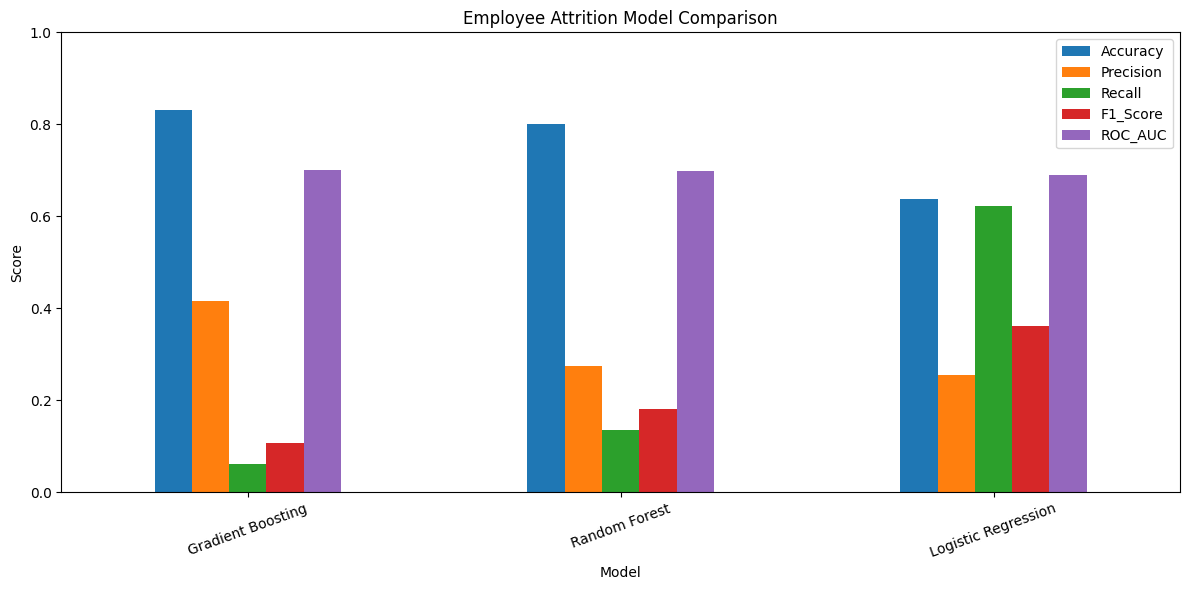

In [ ]:
# ============================================================
# STEP 12: MODEL COMPARISON
# ============================================================

model_outputs = {
    "Logistic Regression": (
        lr_predictions,
        lr_probabilities
    ),
    "Random Forest": (
        rf_predictions,
        rf_probabilities
    ),
    "Gradient Boosting": (
        gb_predictions,
        gb_probabilities
    )
}

results = []

for model_name, (predictions, probabilities) in model_outputs.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(
            y_test, probabilities
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)

print("Model Performance Comparison:")
display(results_df.round(4))

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Employee Attrition Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Model ranked highest by ROC-AUC: Gradient Boosting

Confusion Matrix:
[[411   7]
 [ 77   5]]


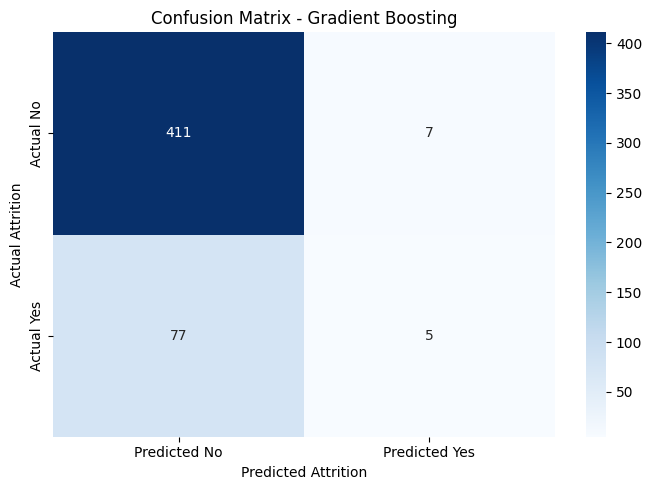

In [ ]:
# ============================================================
# STEP 13: CONFUSION MATRIX
# ============================================================

predictions_by_name = {
    "Logistic Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "Gradient Boosting": gb_predictions
}

best_model_name = results_df.loc[0, "Model"]

best_predictions = predictions_by_name[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

print("Model ranked highest by ROC-AUC:", best_model_name)
print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Attrition")
plt.ylabel("Actual Attrition")
plt.tight_layout()
plt.show()

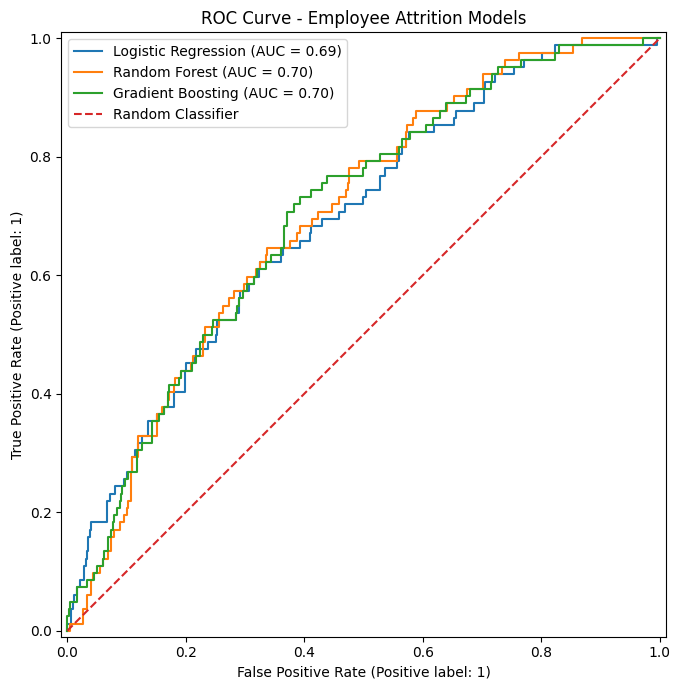

In [ ]:
# ============================================================
# STEP 14: ROC CURVE COMPARISON
# ============================================================

plt.figure(figsize=(9, 7))

for model_name, (_, probabilities) in model_outputs.items():

    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=model_name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve - Employee Attrition Models")
plt.tight_layout()
plt.legend()
plt.show()

Top 10 Features by Random Forest Importance:


,Feature,Importance
1,Monthly_Income,0.164185
10,Income_Per_Experience_Year,0.125082
7,Distance_From_Home,0.119877
8,Training_Hours,0.086364
0,Age,0.077744
2,Years_At_Company,0.068199
3,Years_Experience,0.063856
6,Years_Since_Promotion,0.056641
9,Projects_Completed,0.055556
4,Job_Satisfaction,0.050140


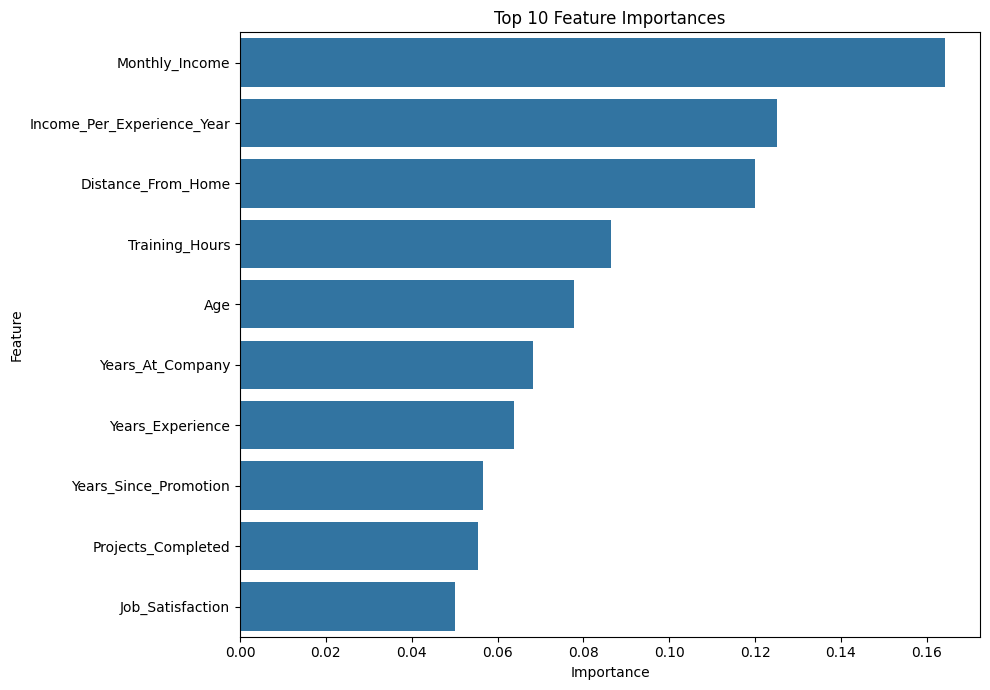

In [ ]:
# ============================================================
# STEP 15: FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Features by Random Forest Importance:")
display(feature_importance.head(10))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# STEP 16: NEW EMPLOYEE PREDICTION
# ============================================================

# Create a sample employee using the same input features
new_employee = pd.DataFrame(
    np.zeros((1, X.shape[1])),
    columns=X.columns
)

new_employee["Age"] = 28
new_employee["Monthly_Income"] = 30000
new_employee["Years_At_Company"] = 2
new_employee["Years_Experience"] = 4
new_employee["Job_Satisfaction"] = 2
new_employee["Work_Life_Balance"] = 2
new_employee["Years_Since_Promotion"] = 2
new_employee["Distance_From_Home"] = 20
new_employee["Training_Hours"] = 10
new_employee["Projects_Completed"] = 3

new_employee["Income_Per_Experience_Year"] = (
    30000 / (4 + 1)
)

# Set categorical indicators according to the sample
new_employee["Overtime_Yes"] = 1

# Ensure columns match the model's training columns
new_employee = new_employee[X.columns]

# Use the model ranked highest by ROC-AUC
model_by_name = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

selected_model = model_by_name[best_model_name]

prediction = selected_model.predict(new_employee)[0]

probability = selected_model.predict_proba(
    new_employee
)[0, 1]

print("Sample Employee Prediction")
print("--------------------------------")
print("Predicted class:", prediction)
print("Simulated model probability:", round(probability, 4))

if prediction == 1:
    print("Model predicts: Attrition")
else:
    print("Model predicts: No Attrition")

print("\nNote: This is a simulated educational prediction,")
print("not a reliable assessment of a real employee.")

Sample Employee Prediction
--------------------------------
Predicted class: 0
Simulated model probability: 0.3853
Model predicts: No Attrition

Note: This is a simulated educational prediction,
not a reliable assessment of a real employee.


In [ ]:
# ============================================================
# STEP 17: EXPORT PROJECT RESULTS
# ============================================================

from google.colab import files

# Save cleaned dataset
df_clean.to_csv(
    "employee_attrition_cleaned.csv",
    index=False
)

# Save model comparison
results_df.to_csv(
    "employee_attrition_model_comparison.csv",
    index=False
)

# Save feature importance
feature_importance.to_csv(
    "employee_attrition_feature_importance.csv",
    index=False
)

print("Project result files created successfully!")

files.download("employee_attrition_model_comparison.csv")

Project result files created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>